# 24. Hợp nhất bảng theo kênh và phân tầng

Hai trục giải thích quan trọng nhất của tuần 3 là trục kênh và trục độ trễ. Mỗi trục hiện đang bị chia đôi giữa hai sổ tay. Trục kênh nằm ở notebook 11, là nơi đo hiệu ứng, và ở notebook 16, là nơi giải thích bất thường thang đo. Trục độ trễ nằm ở notebook 12 với bảy tầng và ở notebook 18 với năm tầng sau khi gộp.

Việc để nguyên bốn bảng rời sẽ gây hai lỗi trong báo cáo. Thứ nhất, người đọc thấy một kênh bị gắn cờ bất thường ở một chỗ nhưng không thấy câu giải thích ở chỗ khác. Thứ hai, hai cách chia tầng dễ bị trích lẫn lộn, trong khi chỉ một trong hai cách đủ năng lực thống kê ở tần cùng.

Sổ tay này dựng một bảng kênh duy nhất và một bảng phân tầng duy nhất, áp luôn ba đính chính đã xác định ở bước rà soát. Không huấn luyện mô hình. Chi phí dưới hai phút.

> **Vị trí trong chuỗi tái lập:** notebook 24 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 09-Ba_ham_mat_mat_hai_neo, 10-Luoi_nam_hat_giong, 11-Chi_so_theo_nhom_kenh, 12-Phan_tang_theo_do_tre, 13-Moc_trung_binh_dich_chuyen, 14-Doi_chung_moc_manh_nhat, 15-Neo_B_ham_tuyet_doi_nam_hat_giong, 16-Kiem_tra_thang_do_kenh, 17-Neo_theo_nguong_do_phu, 18-Phan_tang_gop_tang_cuoi, 22-Hop_nhat_chi_so, 23-Kiem_dinh_dong_nhat.
>
> **Thư mục kết quả:** `Output/processed/w3_artefacts_tong_hop/`.
>
> **Mã định danh nội bộ:** `W3.W4_28`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_artefacts_tong_hop"  #@param {type:"string"}
NGUONG_SO_MUC_IT = 10  #@param {type:"integer"}
NGUONG_TY_SO_DUOI = 10.0  #@param {type:"number"}
TANG_CHINH_THUC = "W3_25"  #@param ["W3_25", "W3_19"]
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:55:03
run_tag      w3_artefacts_tong_hop
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


In [4]:
# Đợt hợp nhất dùng thêm hai thư mục con để tách bảng và gói nộp.
OUT_PROC = OUT / "processed"
BANG = RUN_DIR / "bang"
GOI = RUN_DIR / "goi"
for d in (BANG, GOI):
    d.mkdir(parents=True, exist_ok=True)


def ghi_bang(ten, cot, hang):
    """Ghi một bảng ra tệp CSV, dùng bảng mã có dấu hiệu thứ tự byte cho Excel."""
    import csv
    duong = BANG / ten
    with open(duong, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(cot)
        for r in hang:
            w.writerow([r.get(k, "") for k in cot])
    print("Đã ghi bảng", ten, "|", len(hang), "dòng |",
          duong.stat().st_size, "byte")
    return duong


def ghi_json(ten, doi_tuong):
    """Ghi một tệp tổng hợp, luôn giữ nguyên dấu tiếng Việt."""
    duong = RUN_DIR / ten
    duong.write_text(json.dumps(doi_tuong, ensure_ascii=False, indent=1),
                     encoding="utf-8")
    print("Đã ghi tệp", ten, "|", duong.stat().st_size, "byte")
    return duong


print("Thư mục bảng:", BANG)
print("Thư mục gói :", GOI)


Thư mục bảng: /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/bang
Thư mục gói : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/goi


In [5]:
# Danh mục mười lần chạy của tuần 3, khai báo tường minh theo ba thành phần:
# Mã sổ tay, tên thư mục con và tên tệp tổng hợp mà sổ tay đó đã ghi ra.
DANH_MUC_W3 = [
    ("W3_16", "w3_16_ba_ham_mat_mat_hai_neo", "W3_ba_ham_mat_mat_hai_neo.json"),
    ("W3_17", "w3_17_luoi_nam_hat_giong", "W3_luoi_nam_hat_giong.json"),
    ("W3_18", "w3_18_chi_so_theo_nhom_kenh", "W3_chi_so_theo_nhom_kenh.json"),
    ("W3_19", "w3_19_phan_tang_theo_do_tre", "W3_phan_tang_theo_do_tre.json"),
    ("W3_20", "w3_20_moc_trung_binh_dich_chuyen",
     "W3_moc_trung_binh_dich_chuyen.json"),
    ("W3_21", "w3_21_doi_chung_moc_manh_nhat", "W3_doi_chung_moc_manh_nhat.json"),
    ("W3_22", "w3_22_neo_b_ham_tuyet_doi_nam_hat_giong",
     "W3_neo_b_mae_nam_hat_giong.json"),
    ("W3_23", "w3_23_kiem_tra_thang_do_kenh", "W3_kiem_tra_thang_do_kenh.json"),
    ("W3_24", "w3_24_neo_theo_nguong_do_phu", "W3_neo_theo_nguong_do_phu.json"),
    ("W3_25", "w3_25_phan_tang_gop_tang_cuoi",
     "W3_phan_tang_gop_tang_cuoi.json"),
]


def doc_tong_hop(ma):
    """Đọc tệp tổng hợp của một sổ tay tuần 3 theo mã sổ tay."""
    for m, thu_muc, ten_tep in DANH_MUC_W3:
        if m == ma:
            duong = OUT / "processed" / thu_muc / ten_tep
            assert duong.exists(), "Không thấy " + str(duong)
            return json.loads(duong.read_text())
    raise KeyError("Không có mã sổ tay " + str(ma))


CO_MAT, THIEU = [], []
for ma, thu_muc, ten_tep in DANH_MUC_W3:
    duong = OUT / "processed" / thu_muc / ten_tep
    (CO_MAT if duong.exists() else THIEU).append(ma)
print("Lần chạy đã có tệp tổng hợp:", ", ".join(CO_MAT))
print("Lần chạy còn thiếu        :", ", ".join(THIEU) if THIEU else "không có")
assert not THIEU, ("Còn thiếu tệp tổng hợp của " + ", ".join(THIEU) +
                   ". Hãy chạy lại các sổ tay đó trước khi hợp nhất.")


Lần chạy đã có tệp tổng hợp: W3_16, W3_17, W3_18, W3_19, W3_20, W3_21, W3_22, W3_23, W3_24, W3_25
Lần chạy còn thiếu        : không có


In [6]:
# Mọi sổ tay từ đây trở đi đọc tệp hợp nhất chứ không tự quét thư mục.
TEP_HOP_NHAT = RUN_DIR / "W3_HOP_NHAT_CHI_SO.json"
assert TEP_HOP_NHAT.exists(), (
    "Không thấy " + str(TEP_HOP_NHAT) + ". Hãy chạy notebook 22 và notebook 23 trước.")
HOP_NHAT = json.loads(TEP_HOP_NHAT.read_text())
# Chỉ nhận tệp hợp nhất có phạm vi quét khoá ở tuần 3.
assert HOP_NHAT.get("phien_ban_hop_nhat") == "W3.W4_26", (
    "Tệp hợp nhất chưa được sinh từ notebook 22. Hãy chạy notebook 22 trước.")
print("Phạm vi quét của tệp hợp nhất: tới tuần", HOP_NHAT.get("pham_vi_tuan_toi_da"))
GOC = HOP_NHAT["tong_hop_goc"]
MSE_MOC = HOP_NHAT["mse_persistence"]
MAE_MOC = HOP_NHAT["mae_persistence"]
print("Đã đọc tệp hợp nhất, gồm", len(GOC), "lần chạy gốc của tuần 3")
print("Số cấu hình đã hợp nhất  :", HOP_NHAT["so_cau_hinh"])
print("Số phép kiểm định đã có:",
      HOP_NHAT.get("kiem_dinh", {}).get("so_phep", 0))


Phạm vi quét của tệp hợp nhất: tới tuần 3
Đã đọc tệp hợp nhất, gồm 13 lần chạy gốc của tuần 3
Số cấu hình đã hợp nhất  : 18
Số phép kiểm định đã có: 13


## 2. Bảng kênh hợp nhất

Ba mươi bảy kênh được ghép theo tên kênh. Bên hiệu ứng cung cấp độ phủ, tỷ lệ trùng neo, sai số của hai neo và hiệu ứng. Bên thang đo cung cấp độ lệch chuẩn sau chuẩn hoá, số mức giá trị, tỷ số đuôi và các tham số chuẩn hoá gốc.

Việc ghép theo tên kênh được kiểm tra hai chiều, vì nếu một bên thiếu kênh thì bảng hợp nhất sẽ lặng lẽ bỏ mất dòng đó và không ai phát hiện ra.

In [7]:
BANG_18 = {r["kenh"]: r for r in GOC["W3_18"]["bang_kenh"]}
BANG_23 = {r["kenh"]: r for r in GOC["W3_23"]["bang_thang_do"]}
chi_co_18 = sorted(set(BANG_18) - set(BANG_23))
chi_co_23 = sorted(set(BANG_23) - set(BANG_18))
print("Số kênh bên hiệu ứng:", len(BANG_18))
print("Số kênh bên thang đo:", len(BANG_23))
print("Chỉ có ở bên hiệu ứng:", chi_co_18 if chi_co_18 else "không có")
print("Chỉ có ở bên thang đo:", chi_co_23 if chi_co_23 else "không có")
assert not chi_co_18 and not chi_co_23, "Hai bảng không cùng tập kênh"

BANG_KENH = []
for ten in sorted(BANG_18):
    a, b = BANG_18[ten], BANG_23[ten]
    BANG_KENH.append({
        "kenh": ten,
        "nhom_do_phu": a.get("nhom"),
        "do_phu": a.get("do_phu"),
        "ty_le_trung_neo": a.get("ty_le_trung_neo"),
        "so_diem_muc_tieu": a.get("so_diem_muc_tieu"),
        "mse_neoA": a.get("mse_neoA"),
        "mse_neoB": a.get("mse_neoB"),
        "hieu_ung_mse": a.get("hieu_ung_mse"),
        "hieu_ung_mae": a.get("hieu_ung_mae"),
        "do_lech_chuan_sau_chuan_hoa": b.get("do_lech_chuan"),
        "so_muc_gia_tri": b.get("so_muc_gia_tri"),
        "ty_so_duoi": b.get("ty_so_duoi"),
        "mu_goc": b.get("mu_goc"),
        "sd_goc": b.get("sd_goc"),
        "co_nghi_van_ban_dau": b.get("co_nghi_van"),
        "ly_do_ban_dau": "; ".join(b.get("ly_do", []) or []),
    })
print("")
print("Bảng kênh hợp nhất có", len(BANG_KENH), "dòng và",
      len(BANG_KENH[0]), "cột")


Số kênh bên hiệu ứng: 37
Số kênh bên thang đo: 37
Chỉ có ở bên hiệu ứng: không có
Chỉ có ở bên thang đo: không có

Bảng kênh hợp nhất có 37 dòng và 16 cột


## 3. Áp đính chính về cờ bất thường thang đo

Cờ ban đầu của notebook 16 dùng ba điều kiện, trong đó có điều kiện độ lệch chuẩn sau chuẩn hoá thấp hơn nửa đơn vị. Điều kiện đó đã làm việc cần làm ở bước sàng lọc, nhưng không nên giữ trong bảng công bố, vì một kênh có độ lệch chuẩn thấp sau chuẩn hoá không phải là kênh có thang đo sai: nó có thể đơn thuần là kênh ít biến động trong cửa sổ bốn mươi tám giờ.

Hai điều kiện còn lại mới thật sự chỉ vào vấn đề của thang đo. Số mức giá trị quá ít chỉ ra kênh có bản chất rời rạc hoặc nhị phân, nên phương sai thật rất nhỏ. Tỷ số đuôi quá lớn chỉ ra độ lệch chuẩn tập huấn luyện bị giá trị ngoại lai thổi phồng, tức là dữ liệu thô chứa giá trị không khả thi về mặt sinh lý. Phân biệt được hai cơ chế này là điều kiện để báo cáo đề xuất biện pháp đúng cho từng kênh.

In [8]:
for r in BANG_KENH:
    ly_do = []
    if r["so_diem_muc_tieu"] in (0, 0.0, None):
        ly_do.append("không có phép đo thật trên tập kiểm tra")
    else:
        if r["so_muc_gia_tri"] is not None and r["so_muc_gia_tri"] <= NGUONG_SO_MUC_IT:
            ly_do.append("kênh rời rạc hoặc nhị phân nên phương sai thật rất nhỏ")
        if r["ty_so_duoi"] is not None and r["ty_so_duoi"] > NGUONG_TY_SO_DUOI:
            ly_do.append("độ lệch chuẩn bị giá trị ngoại lai thổi phồng")
    r["ly_do_cong_bo"] = "; ".join(ly_do)
    r["co_nghi_van_cong_bo"] = len(ly_do) > 0

NGHI_VAN = [r for r in BANG_KENH if r["co_nghi_van_cong_bo"]]
GO_CO = [r for r in BANG_KENH
         if r["co_nghi_van_ban_dau"] and not r["co_nghi_van_cong_bo"]]
print("Số kênh bị gắn cờ theo tiêu chí công bố:", len(NGHI_VAN))
for r in NGHI_VAN:
    print("   ", r["kenh"].ljust(14), r["ly_do_cong_bo"])
print("")
print("Số kênh được gỡ cờ so với bản sàng lọc:", len(GO_CO))
for r in GO_CO:
    print("   ", r["kenh"].ljust(14),
          "độ lệch chuẩn sau chuẩn hoá",
          round(float(r["do_lech_chuan_sau_chuan_hoa"]), 4),
          "| số mức", r["so_muc_gia_tri"],
          "| tỷ số đuôi", round(float(r["ty_so_duoi"]), 3))
    print("      kênh này biến động ít trong cửa sổ chứ không sai thang đo,")
    print("      nên sai số nhỏ của nó là tín hiệu thật và phải được giữ.")


Số kênh bị gắn cờ theo tiêu chí công bố: 5
    MechVent       kênh rời rạc hoặc nhị phân nên phương sai thật rất nhỏ
    TropI          không có phép đo thật trên tập kiểm tra
    TropT          không có phép đo thật trên tập kiểm tra
    WBC            độ lệch chuẩn bị giá trị ngoại lai thổi phồng
    pH             độ lệch chuẩn bị giá trị ngoại lai thổi phồng

Số kênh được gỡ cờ so với bản sàng lọc: 0


## 4. Tương quan giữa độ phủ và hiệu ứng, tính lại có loại điểm đòn gánh

Hệ số tương quan giữa độ lệch chuẩn và sai số của neo bước cuối được báo ở notebook 16 không nên trích nguyên, vì đại đa số kênh có độ lệch chuẩn sát một đơn vị, khiến toàn bộ hệ số bị một điểm định đoạt. Ô này định lượng đúng điều đó: đếm số kênh nằm trong dải hẹp quanh một đơn vị, rồi tính lại hệ số sau khi loại các điểm có cờ. Nếu hệ số đổi dấu hoặc sụp về không thì báo cáo không được dùng nó làm bằng chứng.

Tương quan giữa độ phủ và hiệu ứng thì khác: nó không bị hiện tượng này, vì độ phủ trải từ bảy phần trăm đến chín mươi phần trăm. Nó được tính lại ở đây để khẳng định con số có thể trích an toàn.

In [9]:
co_do = [r for r in BANG_KENH if r["so_diem_muc_tieu"] not in (0, 0.0, None)]
sd = np.array([float(r["do_lech_chuan_sau_chuan_hoa"]) for r in co_do])
mse_a = np.array([float(r["mse_neoA"]) for r in co_do])
trong_dai = int(np.sum(np.abs(sd - 1.0) < 0.01))
print("Số kênh có đo trên tập kiểm tra:", len(co_do))
print("Số kênh có độ lệch chuẩn cách một đơn vị dưới một phần trăm:", trong_dai)
print("Tỷ lệ:", round(100.0 * trong_dai / len(co_do), 2), "phần trăm")
print("")
he_so_day_du = float(np.corrcoef(sd, mse_a)[0, 1])
giu = [i for i, r in enumerate(co_do) if not r["co_nghi_van_cong_bo"]]
he_so_sau_loai = float(np.corrcoef(sd[giu], mse_a[giu])[0, 1]) if len(giu) > 2 else float("nan")
print("Hệ số tương quan độ lệch chuẩn và sai số neo bước cuối")
print("   tính trên toàn bộ kênh :", round(he_so_day_du, 6))
print("   sau khi loại kênh có cờ:", round(he_so_sau_loai, 6), "trên", len(giu), "kênh")
print("   kết luận: hệ số này không ổn định, không trích làm bằng chứng.")
print("")
do_phu = np.array([float(r["do_phu"]) for r in co_do])
hieu_ung = np.array([float(r["hieu_ung_mse"]) for r in co_do])
he_so_do_phu = float(np.corrcoef(do_phu, hieu_ung)[0, 1])
print("Hệ số tương quan độ phủ và hiệu ứng:", round(he_so_do_phu, 6))
print("   độ phủ trải từ", round(float(do_phu.min()), 4), "đến",
      round(float(do_phu.max()), 4), "nên con số này trích được.")
print("   so với bản gốc của notebook 11:",
      round(float(GOC["W3_18"]["tuong_quan_do_phu_va_hieu_ung"]), 6))


Số kênh có đo trên tập kiểm tra: 35
Số kênh có độ lệch chuẩn cách một đơn vị dưới một phần trăm: 34
Tỷ lệ: 97.14 phần trăm

Hệ số tương quan độ lệch chuẩn và sai số neo bước cuối
   tính trên toàn bộ kênh : 0.338109
   sau khi loại kênh có cờ: 0.376906 trên 32 kênh
   kết luận: hệ số này không ổn định, không trích làm bằng chứng.

Hệ số tương quan độ phủ và hiệu ứng: 0.570158
   độ phủ trải từ 0.0021 đến 0.914 nên con số này trích được.
   so với bản gốc của notebook 11: 0.570158


## 5. Bảng phân tầng hợp nhất

Hai cách chia tầng được giữ cả hai trong một bảng, kèm cột cho biết dòng thuộc cách chia nào và dòng nào là dòng chính thức. Cách chia năm tầng được chọn làm chính thức, vì tầng trên mười sáu giờ của nó có hơn chín nghìn điểm và đạt mức ý nghĩa, trong khi tầng trên ba mươi sáu giờ của cách chia bảy tầng chỉ có tám trăm chín mươi chín điểm và không đạt.

Giữ cả hai cách chia là lựa chọn có chủ đích, không phải dư thừa: cách chia bảy tầng vẫn cần cho phụ lục, vì nó cho thấy hình dạng chi tiết của quan hệ ở đuôi.

In [10]:
def doc_tang(ma, nhan_chia):
    d = GOC[ma]
    hang = []
    dong_gop = d.get("dong_gop", {})
    for ten, v in d["phan_tang"].items():
        hang.append({
            "cach_chia": nhan_chia,
            "nguon": ma,
            "tang": ten,
            "so_diem": v.get("so_diem"),
            "ty_le_diem": v.get("ty_le_diem"),
            "mse_neoA": v.get("mse_neoA"),
            "mse_neoB": v.get("mse_neoB"),
            "hieu_mse": v.get("hieu_mse"),
            "hieu_mse_ci": v.get("hieu_mse_ci"),
            "p_mse": v.get("p_mse"),
            "hieu_mae": v.get("hieu_mae"),
            "p_mae": v.get("p_mae"),
            "dong_gop_vao_hieu_ung_chung": dong_gop.get(ten),
        })
    return hang


BANG_TANG = doc_tang("W3_25", "năm tầng") + doc_tang("W3_19", "bảy tầng")
for r in BANG_TANG:
    r["la_dong_chinh_thuc"] = bool(r["nguon"] == TANG_CHINH_THUC)
    p = r["p_mse"]
    r["dat_muc_y_nghia"] = bool(p is not None and float(p) < 0.05)

print("Cách chia chính thức:", TANG_CHINH_THUC)
print("")
for r in BANG_TANG:
    print(("[chính]" if r["la_dong_chinh_thuc"] else "[phụ ]"),
          r["tang"].ljust(32),
          str(r["so_diem"]).rjust(6), "điểm",
          "| hiệu sai số bình phương", str(round(float(r["hieu_mse"]), 6)).rjust(11),
          "| giá trị p", r["p_mse"],
          "| đạt mức ý nghĩa", r["dat_muc_y_nghia"])
print("")
chinh = [r for r in BANG_TANG if r["la_dong_chinh_thuc"]]
khong_dat = [r["tang"] for r in chinh if not r["dat_muc_y_nghia"]]
print("Số tầng chính thức đạt mức ý nghĩa:",
      sum(1 for r in chinh if r["dat_muc_y_nghia"]), "trên", len(chinh))
print("Tầng chưa đạt:", ", ".join(khong_dat) if khong_dat else "không có")


Cách chia chính thức: W3_25

[chính] 1 đến 2 giờ                      17851.0 điểm | hiệu sai số bình phương   -0.014152 | giá trị p 0.0 | đạt mức ý nghĩa True
[chính] 3 đến 4 giờ                      21043.0 điểm | hiệu sai số bình phương   -0.031623 | giá trị p 0.0 | đạt mức ý nghĩa True
[chính] 5 đến 8 giờ                      40933.0 điểm | hiệu sai số bình phương   -0.029616 | giá trị p 0.0 | đạt mức ý nghĩa True
[chính] 9 đến 16 giờ                     45922.0 điểm | hiệu sai số bình phương   -0.061731 | giá trị p 0.0 | đạt mức ý nghĩa True
[chính] trên 16 giờ                      9092.0 điểm | hiệu sai số bình phương   -0.236214 | giá trị p 0.0 | đạt mức ý nghĩa True
[chính] không có phép đo trong cửa sổ    1911.0 điểm | hiệu sai số bình phương    0.001236 | giá trị p 0.316 | đạt mức ý nghĩa False
[phụ ] 1 đến 2 giờ                      17851.0 điểm | hiệu sai số bình phương   -0.014152 | giá trị p 0.0 | đạt mức ý nghĩa True
[phụ ] 3 đến 4 giờ                      21043.0 điểm |

## 6. Kiểm tra tính đơn điệu và tổng đóng góp

Hai phép tự kiểm tra được làm ở đây. Thứ nhất, tổng đóng góp của các tầng phải bằng một, vì hiệu ứng chung là tổng có trọng số của hiệu ứng theo tầng. Nếu tổng lệch thì phép phân rã đã sai ở đâu đó. Thứ hai, kiểm tra hiệu ứng có tăng đơn điệu theo độ trễ hay không. Kết quả không đơn điệu phải được báo cáo nguyên dạng, vì đó là một đặc điểm thật của dữ liệu, không phải lỗi cần làm mờ.

In [11]:
for nguon in ("W3_25", "W3_19"):
    hang = [r for r in BANG_TANG if r["nguon"] == nguon]
    dg = [r["dong_gop_vao_hieu_ung_chung"] for r in hang
          if r["dong_gop_vao_hieu_ung_chung"] is not None]
    print(nguon, "| số tầng", len(hang),
          "| tổng đóng góp", round(float(sum(dg)), 6) if dg else "chưa có")
    co_do_tang = [r for r in hang if "không có phép đo" not in r["tang"]]
    hieu = [float(r["hieu_mse"]) for r in co_do_tang]
    don_dieu = all(hieu[i] >= hieu[i + 1] for i in range(len(hieu) - 1))
    print("     hiệu ứng mạnh dần đơn điệu theo độ trễ:", don_dieu)
    if not don_dieu:
        for i in range(len(hieu) - 1):
            if hieu[i] < hieu[i + 1]:
                print("     điểm phá đơn điệu:", co_do_tang[i]["tang"], "so với",
                      co_do_tang[i + 1]["tang"])
    if len(co_do_tang) > 2:
        thu_tu = np.arange(len(co_do_tang), dtype=np.float64)
        print("     tương quan thứ tự tầng và hiệu ứng:",
              round(float(np.corrcoef(thu_tu, np.array(hieu))[0, 1]), 6))
    print("")
hai_tang_cuoi = [r for r in BANG_TANG
                 if r["nguon"] == "W3_25" and r["tang"] in
                 ("9 đến 16 giờ", "trên 16 giờ")]
if hai_tang_cuoi:
    ty_le = sum(float(r["ty_le_diem"]) for r in hai_tang_cuoi)
    dg = sum(float(r["dong_gop_vao_hieu_ung_chung"]) for r in hai_tang_cuoi)
    print("Hai tầng độ trễ dài nhất giữ", round(100.0 * ty_le, 2),
          "phần trăm số điểm")
    print("      nhưng mang", round(100.0 * dg, 2), "phần trăm hiệu ứng chung.")
    print("      Đây là lập luận trọng tâm của toàn bộ luận điểm về neo.")
else:
    print("Không tìm thấy hai tầng độ trễ dài nhất trong notebook 18.")


W3_25 | số tầng 6 | tổng đóng góp 1.0
     hiệu ứng mạnh dần đơn điệu theo độ trễ: False
     điểm phá đơn điệu: 3 đến 4 giờ so với 5 đến 8 giờ
     tương quan thứ tự tầng và hiệu ứng: -0.815591

W3_19 | số tầng 7 | tổng đóng góp chưa có
     hiệu ứng mạnh dần đơn điệu theo độ trễ: False
     điểm phá đơn điệu: 3 đến 4 giờ so với 5 đến 8 giờ
     điểm phá đơn điệu: 17 đến 36 giờ so với trên 36 giờ
     tương quan thứ tự tầng và hiệu ứng: -0.818698

Hai tầng độ trễ dài nhất giữ 40.23 phần trăm số điểm
      nhưng mang 70.07 phần trăm hiệu ứng chung.
      Đây là lập luận trọng tâm của toàn bộ luận điểm về neo.


## 7. Hình ba và hình bốn của báo cáo

Hình ba đặt hiệu ứng theo kênh trên trục độ phủ, dùng trục dọc theo thang logarit vì hiệu ứng trải trên gần ba bậc độ lớn. Hình bốn đặt hiệu ứng theo tầng độ trễ cạnh đóng góp tương ứng, để thấy ngay sự lệch giữa tỷ lệ số điểm và tỷ lệ đóng góp.

Số kênh đưa lên hình: 35
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/figures/W3_T03_hieu_ung_theo_kenh.png


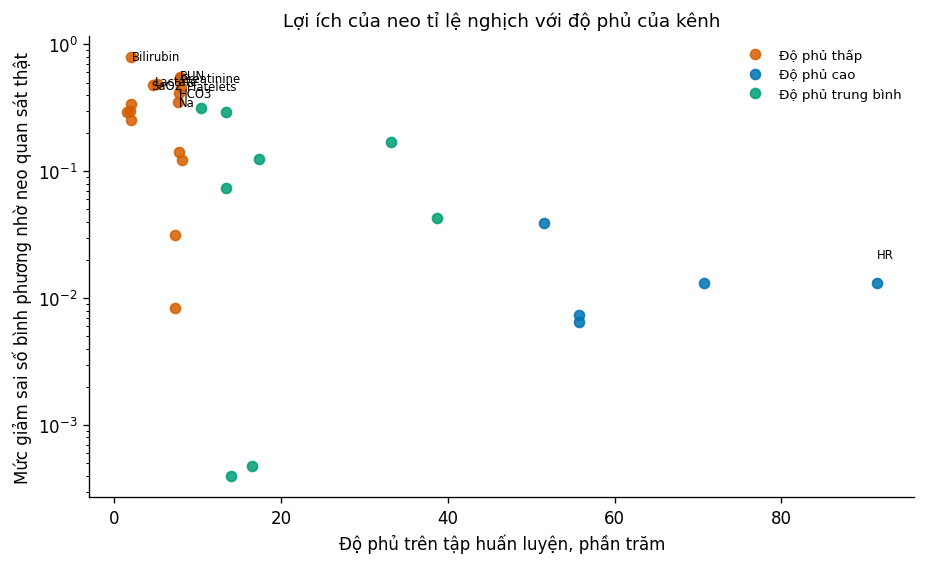

In [12]:
# Thư viện dàn nhãn không có sẵn trên Colab; cài khi thiếu, nếu không cài được thì giữ nhãn tại chỗ.
try:
    from adjustText import adjust_text
except ImportError:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "adjustText"], check=True)
        from adjustText import adjust_text
    except Exception:
        def adjust_text(*args, **kwargs):
            print("Không cài được adjustText, giữ nguyên vị trí nhãn")

# Danh sách kênh có phép đo thật, dựng lại tại chỗ để không phụ thuộc
# vào biến co_do của ô khác (ô phân tầng từng dùng trùng tên này).
co_do_kenh = [r for r in BANG_KENH
              if r["so_diem_muc_tieu"] not in (0, 0.0, None)
              and r["hieu_ung_mse"] is not None and r["do_phu"] is not None]
print("Số kênh đưa lên hình:", len(co_do_kenh))

fig, ax = plt.subplots(figsize=(7.6, 4.6))
nhom_mau = {"phu_cao": PALETTE[0], "phu_trung_binh": PALETTE[2],
            "phu_thap": PALETTE[1]}
nhom_ten = {"phu_cao": "Độ phủ cao", "phu_trung_binh": "Độ phủ trung bình",
            "phu_thap": "Độ phủ thấp"}
da_ve = set()

for r in co_do_kenh:
    lo = -float(r["hieu_ung_mse"])
    if lo <= 0:
        continue
    nhom = r["nhom_do_phu"]
    ax.plot([100.0 * float(r["do_phu"])], [lo], "o",
            color=nhom_mau.get(nhom, PALETTE[4]), ms=6, alpha=0.85,
            label=nhom_ten.get(nhom, nhom) if nhom not in da_ve else None)
    da_ve.add(nhom)

# Gom tất cả các text cần ghi chú vào một danh sách
texts = []
for r in co_do_kenh:
    lo = -float(r["hieu_ung_mse"])
    if lo > 0.35 or (lo > 0 and 100.0 * float(r["do_phu"]) > 80):
        # Dùng ax.text thay vì ax.annotate để dễ dàng dùng adjust_text
        texts.append(ax.text(100.0 * float(r["do_phu"]), lo, r["kenh"], fontsize=7))

# Tự động điều chỉnh vị trí các chữ để không bị đè lên nhau, có thêm đường kẻ nối mờ
adjust_text(texts, arrowprops=dict(arrowstyle="-", color='gray', lw=0.5))

ax.set_yscale("log")
ax.set_xlabel("Độ phủ trên tập huấn luyện, phần trăm")
ax.set_ylabel("Mức giảm sai số bình phương nhờ neo quan sát thật")
ax.set_title("Lợi ích của neo tỉ lệ nghịch với độ phủ của kênh")
ax.legend(fontsize=8, loc="upper right")
luu_hinh(fig, "W3_T03_hieu_ung_theo_kenh.png")
plt.show()


Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/figures/W3_T04_phan_tang_do_tre.png


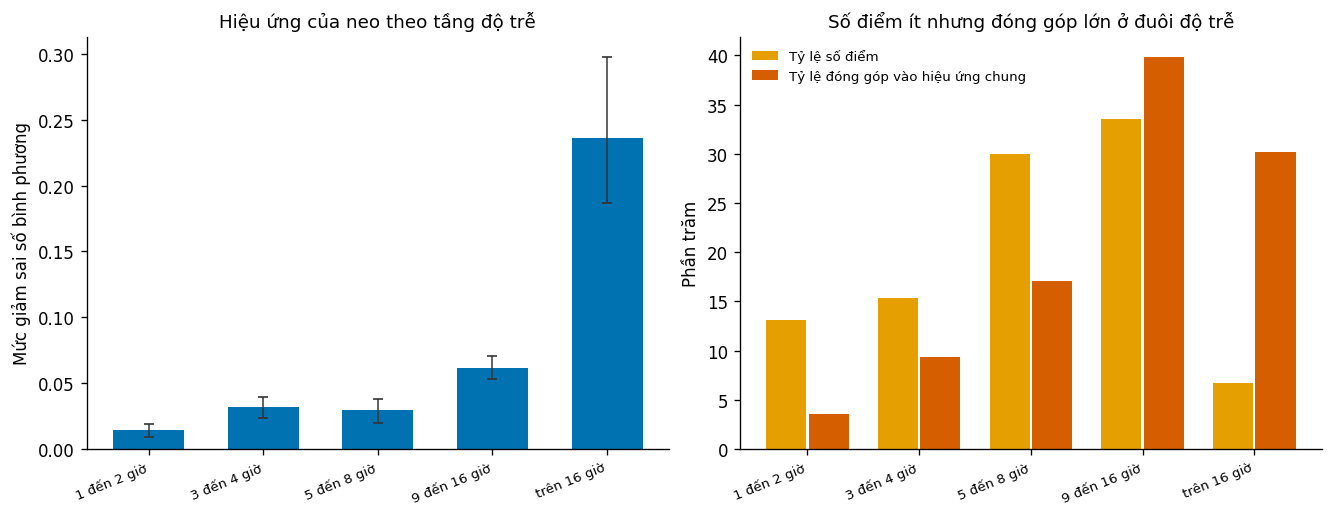

In [13]:
chinh_co_do = [r for r in BANG_TANG
               if r["la_dong_chinh_thuc"] and "không có phép đo" not in r["tang"]]
fig, truc = plt.subplots(1, 2, figsize=(11.0, 4.2))
x = np.arange(len(chinh_co_do))
ten_tang = [r["tang"] for r in chinh_co_do]
cao = [-float(r["hieu_mse"]) for r in chinh_co_do]
thap_ci = [-float(r["hieu_mse_ci"][1]) for r in chinh_co_do]
cao_ci = [-float(r["hieu_mse_ci"][0]) for r in chinh_co_do]
loi = np.array([np.array(cao) - np.array(thap_ci), np.array(cao_ci) - np.array(cao)])
truc[0].bar(x, cao, yerr=loi, color=PALETTE[0], width=0.62,
            error_kw={"ecolor": "#333333", "capsize": 3, "lw": 0.9})
truc[0].set_xticks(x)
truc[0].set_xticklabels(ten_tang, rotation=22, ha="right", fontsize=8)
truc[0].set_ylabel("Mức giảm sai số bình phương")
truc[0].set_title("Hiệu ứng của neo theo tầng độ trễ")
ty_le = [100.0 * float(r["ty_le_diem"]) for r in chinh_co_do]
dong_gop = [100.0 * float(r["dong_gop_vao_hieu_ung_chung"]) for r in chinh_co_do]
truc[1].bar(x - 0.19, ty_le, width=0.36, color=PALETTE[4],
            label="Tỷ lệ số điểm")
truc[1].bar(x + 0.19, dong_gop, width=0.36, color=PALETTE[1],
            label="Tỷ lệ đóng góp vào hiệu ứng chung")
truc[1].set_xticks(x)
truc[1].set_xticklabels(ten_tang, rotation=22, ha="right", fontsize=8)
truc[1].set_ylabel("Phần trăm")
truc[1].set_title("Số điểm ít nhưng đóng góp lớn ở đuôi độ trễ")
truc[1].legend(fontsize=8)
luu_hinh(fig, "W3_T04_phan_tang_do_tre.png")
plt.show()


## 8. Ghi bảng và cập nhật tệp hợp nhất

In [14]:
COT_KENH = ["kenh", "nhom_do_phu", "do_phu", "ty_le_trung_neo",
            "so_diem_muc_tieu", "mse_neoA", "mse_neoB", "hieu_ung_mse",
            "hieu_ung_mae", "do_lech_chuan_sau_chuan_hoa", "so_muc_gia_tri",
            "ty_so_duoi", "mu_goc", "sd_goc", "co_nghi_van_cong_bo",
            "ly_do_cong_bo", "co_nghi_van_ban_dau", "ly_do_ban_dau"]
COT_TANG = ["cach_chia", "nguon", "la_dong_chinh_thuc", "tang", "so_diem",
            "ty_le_diem", "mse_neoA", "mse_neoB", "hieu_mse", "hieu_mse_ci",
            "p_mse", "dat_muc_y_nghia", "hieu_mae", "p_mae",
            "dong_gop_vao_hieu_ung_chung"]
ghi_bang("W3_bang_kenh_hop_nhat.csv", COT_KENH, BANG_KENH)
ghi_bang("W3_bang_phan_tang_hop_nhat.csv", COT_TANG, BANG_TANG)

HOP_NHAT["truc_giai_thich"] = {
    "hop_nhat_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "tang_chinh_thuc": TANG_CHINH_THUC,
    "so_kenh": len(BANG_KENH),
    "kenh_co_co_cong_bo": [r["kenh"] for r in NGHI_VAN],
    "kenh_duoc_go_co": [r["kenh"] for r in GO_CO],
    "tuong_quan_do_lech_va_mse_neoA_toan_bo": he_so_day_du,
    "tuong_quan_do_lech_va_mse_neoA_sau_loai": he_so_sau_loai,
    "so_kenh_do_lech_chuan_sat_mot": trong_dai,
    "tuong_quan_do_phu_va_hieu_ung": he_so_do_phu,
    "bang_kenh": BANG_KENH,
    "bang_phan_tang": BANG_TANG,
}
ghi_json("W3_HOP_NHAT_CHI_SO.json", HOP_NHAT)
print("")
print("Bước kế tiếp: chạy notebook 25 để dựng nốt các hình chính của báo cáo.")


Đã ghi bảng W3_bang_kenh_hop_nhat.csv | 37 dòng | 9005 byte
Đã ghi bảng W3_bang_phan_tang_hop_nhat.csv | 13 dòng | 3089 byte
Đã ghi tệp W3_HOP_NHAT_CHI_SO.json | 224893 byte

Bước kế tiếp: chạy notebook 25 để dựng nốt các hình chính của báo cáo.
